# Análise de Mortes Violentas por Local de Ocorrência
## Sprint 1 - PyAnalytics

In [58]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [59]:
df = pd.read_csv("../../data/processed/sim_sc_processado_analitico.csv")
df.head()

C:\Users\lucas\AppData\Local\Temp\ipykernel_12804\2361278397.py:1: DtypeWarning: Columns (0: DTOBITO, 1: DTNASC, 2: RACACOR, 3: ESC, 4: IDADEMAE, 5: ESCMAE, 6: GESTACAO, 7: LINHAA, 8: LINHAB, 9: LINHAC, 10: LINHAD, 11: LINHAII) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../../data/processed/sim_sc_processado_analitico.csv")


,CONTADOR,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,...,RACACOR_COD,LOCOCOR_COD,IDADE_COD,IDADE_ANOS,ANO_OBITO,ANO_NASC,DATA_OBITO_VALIDA,DATA_NASC_VALIDA,SC_RESIDENCIA,SC_OCORRENCIA
0,2527,2,2000-12-12,NaN,800.0,NaN,1933-11-01,467.0,Masculino,Preta,...,2.0,3.0,467.0,67.0,2000.0,1933.0,True,True,False,True
1,14333,2,2000-11-19,NaN,850.0,NaN,1978-10-20,422.0,Masculino,Branca,...,1.0,5.0,422.0,22.0,2000.0,1978.0,True,True,False,True
2,14334,2,2000-10-16,NaN,842.0,NaN,1910-05-31,490.0,Masculino,Branca,...,1.0,1.0,490.0,90.0,2000.0,1910.0,True,True,False,True
3,51178,2,2000-07-05,NaN,NaN,NaN,1949-12-10,450.0,Masculino,Parda,...,4.0,9.0,450.0,50.0,2000.0,1949.0,True,True,False,True
4,109,2,2000-02-02,NaN,800.0,NaN,1979-05-07,420.0,Masculino,Branca,...,1.0,5.0,420.0,20.0,2000.0,1979.0,True,True,False,True


## 1. Preparação dos Dados

Antes de qualquer análise, é necessário entender a estrutura dos dados, identificar valores ausentes e garantir que o recorte utilizado é adequado para responder às perguntas propostas.

In [60]:
print(df.columns.tolist())
df.info()

['CONTADOR', 'TIPOBITO', 'DTOBITO', 'HORAOBITO', 'NATURAL', 'CODMUNNATU', 'DTNASC', 'IDADE', 'SEXO', 'RACACOR', 'ESTCIV', 'ESC', 'ESC2010', 'SERIESCFAL', 'OCUP', 'CODMUNRES', 'LOCOCOR', 'CODMUNOCOR', 'IDADEMAE', 'ESCMAE', 'ESCMAE2010', 'SERIESCMAE', 'OCUPMAE', 'QTDFILVIVO', 'QTDFILMORT', 'GRAVIDEZ', 'GESTACAO', 'PARTO', 'OBITOPARTO', 'PESO', 'OBITOGRAV', 'OBITOPUERP', 'ASSISTMED', 'EXAME', 'CIRURGIA', 'NECROPSIA', 'CAUSABAS', 'LINHAA', 'LINHAB', 'LINHAC', 'LINHAD', 'LINHAII', 'CIRCOBITO', 'ACIDTRAB', 'FONTE', 'DTOBITO_BRUTO', 'DTNASC_BRUTO', 'SEXO_COD', 'RACACOR_COD', 'LOCOCOR_COD', 'IDADE_COD', 'IDADE_ANOS', 'ANO_OBITO', 'ANO_NASC', 'DATA_OBITO_VALIDA', 'DATA_NASC_VALIDA', 'SC_RESIDENCIA', 'SC_OCORRENCIA']
<class 'pandas.DataFrame'>
RangeIndex: 1502195 entries, 0 to 1502194
Data columns (total 58 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   CONTADOR           1502195 non-null  int64  
 1   TIPOBITO           1502195

In [61]:
# Verifica valores nulos nas colunas que vamos usar
colunas_interesse = ["LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]
df[colunas_interesse].isnull().sum()

LOCOCOR         2108
IDADE            172
ASSISTMED     262839
CAUSABAS           0
CODMUNOCOR         0
dtype: int64

In [62]:
# Exemplos de linhas nulas em LOCOCOR
print("LOCOCOR nulos")
df[df["LOCOCOR"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

LOCOCOR nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
1288094,111,NaN,419.0,2.0,8147,4207304
1289231,996,NaN,454.0,2.0,9289,4216602
1289313,1078,NaN,480.0,2.0,7989,4205407
1289318,1083,NaN,460.0,2.0,7989,4200606
1289341,1106,NaN,456.0,1.0,2503,4205407
1289342,1107,NaN,454.0,1.0,8199,4200903
1289400,1165,NaN,428.0,1.0,8199,4205407
1289492,1257,NaN,464.0,1.0,486X,4202909
1289494,1259,NaN,491.0,NaN,797X,4202909
1289798,1563,NaN,462.0,NaN,436X,4216305


In [63]:
# Exemplos de linhas nulas em IDADE
print("IDADE nulos")
df[df["IDADE"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

IDADE nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
182746,4166,Hospital,NaN,NaN,P021,420320
188961,10381,Hospital,NaN,NaN,P022,420330
189789,11209,Outros,NaN,NaN,Y098,421580
200900,22320,Hospital,NaN,1.0,P025,421175
1390424,191,Hospital,NaN,1.0,C719,4106902
1390604,371,Outros,NaN,2.0,V892,4106902
1390618,385,NaN,NaN,1.0,K746,4106902
1391487,1254,Via publica,NaN,1.0,V892,4205704
1392249,2016,NaN,NaN,9.0,I219,4207908
1393447,3214,NaN,NaN,1.0,J988,4209003


In [64]:
# Exemplos de linhas nulas em ASSISTMED
print("ASSISTMED nulos")
df[df["ASSISTMED"].isna()][["CONTADOR", "LOCOCOR", "IDADE", "ASSISTMED", "CAUSABAS", "CODMUNOCOR"]].head(10)

ASSISTMED nulos


,CONTADOR,LOCOCOR,IDADE,ASSISTMED,CAUSABAS,CODMUNOCOR
0,2527,Domicilio,467.0,NaN,J449,4216909
1,14333,Outros,422.0,NaN,W698,4211405
2,14334,Hospital,490.0,NaN,J439,4203303
3,51178,Ignorado,450.0,NaN,C786,4207684
4,109,Outros,420.0,NaN,W698,4211900
5,147,Via publica,440.0,NaN,I255,4201950
6,95695,Outros,418.0,NaN,W698,4202107
7,249,Hospital,102.0,NaN,P392,4209102
10,6259,Domicilio,457.0,NaN,C64,4219101
11,51872,Outros,438.0,NaN,X938,4208203


In [65]:
# Verifica duplicatas
duplicatas = df.duplicated()
print(f"Total de linhas duplicadas: {duplicatas.sum()}")
df[duplicatas].head(10)

Total de linhas duplicadas: 0


,CONTADOR,TIPOBITO,DTOBITO,HORAOBITO,NATURAL,CODMUNNATU,DTNASC,IDADE,SEXO,RACACOR,...,RACACOR_COD,LOCOCOR_COD,IDADE_COD,IDADE_ANOS,ANO_OBITO,ANO_NASC,DATA_OBITO_VALIDA,DATA_NASC_VALIDA,SC_RESIDENCIA,SC_OCORRENCIA


### Decisões sobre Valores Ausentes

- **LOCOCOR**: 13 registros sem local de óbito em Araranguá — removidos via `dropna`, pois o local é a variável central da análise. Perda de menos de 0,2%, desprezível.
- **IDADE**: poucos registros ausentes — mantidos. Os gráficos usam `IDADE_ANOS` (derivada pelo pipeline); registros sem idade simplesmente não aparecem no boxplot.
- **ASSISTMED**: expressivo número de ausências no dataset geral de SC. Mantidos e classificados como "Não informado" nos gráficos, sem imputação, para não distorcer a análise.
- **Duplicatas**: nenhuma encontrada.

## Filtro para Araranguá — Mortes Violentas (CID V–Y)

O recorte limita a análise às mortes com causas externas (CID iniciados em V, W, X ou Y), que correspondem a acidentes, homicídios, suicídios e eventos de intenção indeterminada. Óbitos por doenças como AVC e infarto são excluídos.

In [66]:
CODIGO_ARARANGUA = 4201406

# Filtra apenas mortes violentas (causas externas CID V-Y)
mascara_violenta = df["CAUSABAS"].astype(str).str.match(r"^[V-Y]", na=False)

df_limpo = (
    df[(df["CODMUNOCOR"] == CODIGO_ARARANGUA) & mascara_violenta]
    .dropna(subset=["LOCOCOR"])
    .copy()
)

# Mapeia ASSISTMED para texto legível
mapa_assistmed = {1.0: "Sim", 2.0: "Não", 9.0: "Ignorado"}
df_limpo["ASSISTMED_LABEL"] = df_limpo["ASSISTMED"].map(mapa_assistmed).fillna("Não informado")

print(f"Total de mortes violentas em Araranguá: {len(df_limpo)}")

Total de mortes violentas em Araranguá: 450


In [67]:
print(f"Antes do dropna: {len(df[(df['CODMUNOCOR'] == CODIGO_ARARANGUA) & mascara_violenta])}")
print(f"Depois do dropna: {len(df_limpo)}")
print(f"Removidos: {len(df[(df['CODMUNOCOR'] == CODIGO_ARARANGUA) & mascara_violenta]) - len(df_limpo)}")

Antes do dropna: 453
Depois do dropna: 450
Removidos: 3


## Normalização por Habitantes

A taxa por 100.000 habitantes permite comparar Araranguá com outros municípios de tamanhos diferentes, eliminando o viés de municípios maiores simplesmente terem mais óbitos em termos absolutos.

In [68]:
# População de Araranguá — Censo IBGE 2022
POP_ARARANGUA = 107089

taxa_geral = len(df_limpo) / POP_ARARANGUA * 100000
print(f"Taxa de mortalidade violenta em Araranguá: {taxa_geral:.1f} mortes por 100.000 habitantes")

# Taxa por local de ocorrência
contagem_local_raw = df_limpo["LOCOCOR"].value_counts()
taxa_por_local = (contagem_local_raw / POP_ARARANGUA * 100000).round(2)
print("\nTaxa por local (por 100.000 hab):")
print(taxa_por_local)

Taxa de mortalidade violenta em Araranguá: 420.2 mortes por 100.000 habitantes

Taxa por local (por 100.000 hab):
LOCOCOR
Hospital       168.08
Via publica    163.42
Domicilio       41.09
Outros          36.42
Ignorado        11.21
Name: count, dtype: float64


Araranguá apresenta uma taxa de mortalidade violenta que pode ser confrontada com médias estaduais e nacionais. Taxas acima de 20 por 100.000 hab. já são consideradas elevadas pela OMS para mortes por causas externas.

## 2. Análise Comparativa de Proporção (Local x Idade)

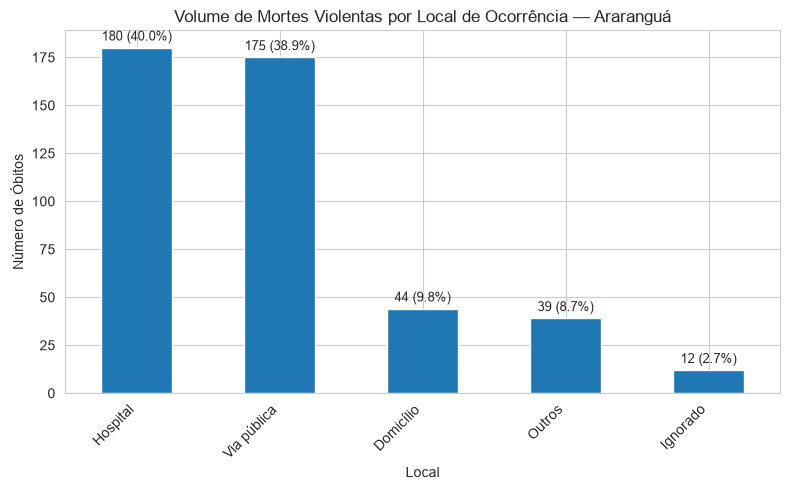

In [69]:
mapa_local = {
    "Hospital": "Hospital",
    "Domicilio": "Domicílio",
    "Via publica": "Via pública",
    "Outro estabelecimento de saude": "OES",
    "Outros": "Outros",
    "Aldeia indigena": "Ald. Indígena",
    "Ignorado": "Ignorado"
}

contagem_local = df_limpo["LOCOCOR"].value_counts()
contagem_local.index = contagem_local.index.map(lambda x: mapa_local.get(x, x))
total = contagem_local.sum()

fig, ax = plt.subplots(figsize=(8,5))
bars = contagem_local.plot(kind="bar", ax=ax)
plt.title("Volume de Mortes Violentas por Local de Ocorrência — Araranguá")
plt.xlabel("Local")
plt.ylabel("Número de Óbitos")
plt.xticks(rotation=45, ha="right")

for bar in ax.patches:
    pct = bar.get_height() / total * 100
    ax.annotate(f"{int(bar.get_height())} ({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

A paridade de óbitos entre a **via pública** e o **hospital** evidencia a alta gravidade imediata dos traumas de trânsito, exigindo mais rigor na fiscalização viária e agilidade no resgate, enquanto a proporção relevante em **domicílios** aponta para violências silenciosas como suicídios e quedas de idosos, ressaltando a necessidade urgente de fortalecer o suporte à saúde mental (CAPS) e a atenção primária no município.

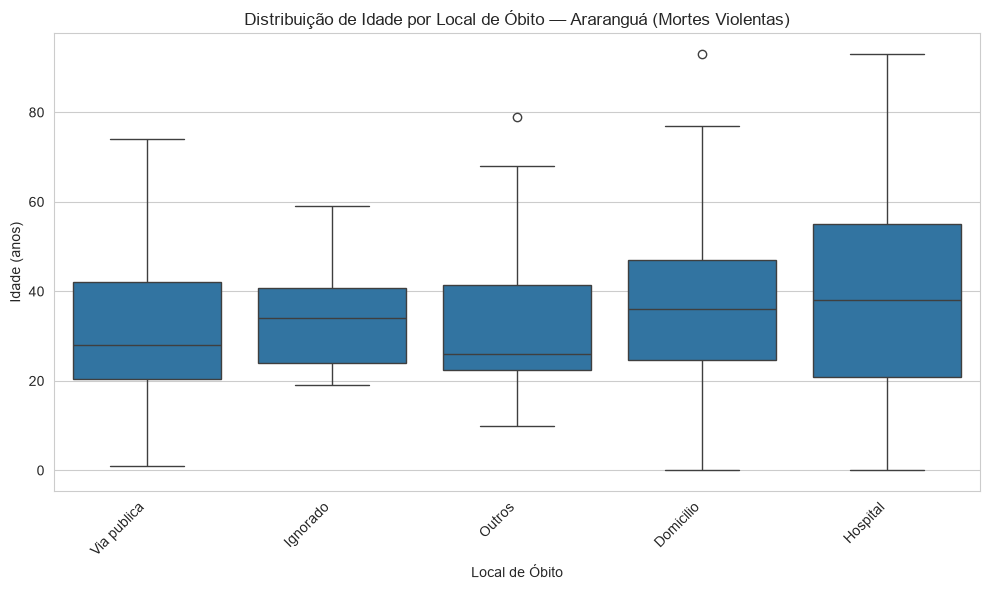

In [70]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df_limpo, x="LOCOCOR", y="IDADE_ANOS")
plt.title("Distribuição de Idade por Local de Óbito — Araranguá (Mortes Violentas)")
plt.xlabel("Local de Óbito")
plt.ylabel("Idade (anos)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

> **Nota:** Os pontos fora das caixas são outliers — casos com idade atípica em relação ao padrão daquele local. A caixa representa 50% dos casos centrais e a linha do meio é a mediana.

A concentração de vítimas jovens na **via pública** reforça o impacto socioeconômico precoce das mortes no trânsito e violência urbana em Araranguá, demandando campanhas focadas na juventude, enquanto a dispersão e idades mais elevadas no **hospital** e **domicílio** evidenciam a necessidade de protocolos específicos de prevenção a quedas e suporte geriátrico no município.

## 3. Indicador de Amparo Médico

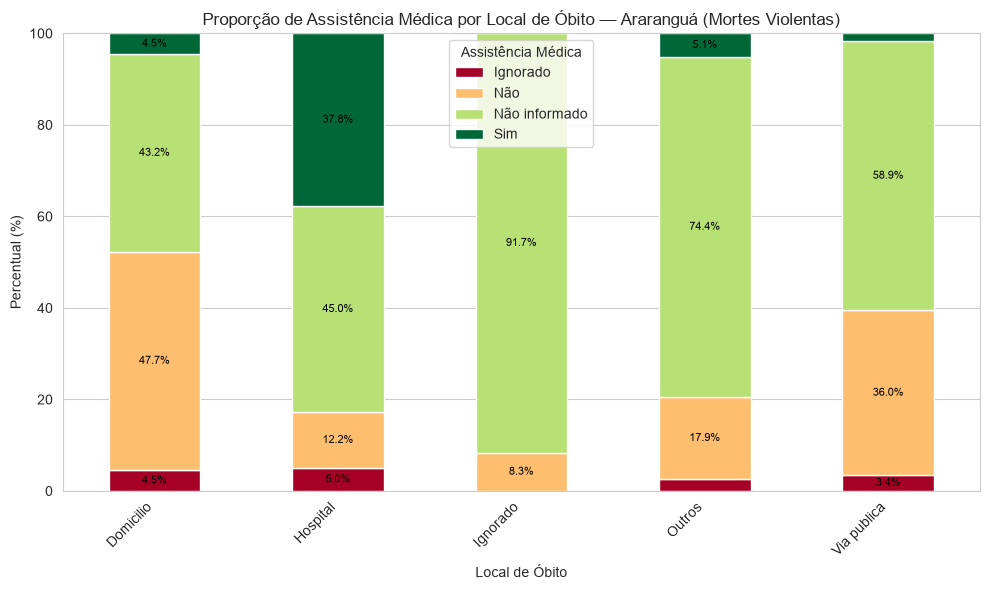

In [71]:
tabela_assist = pd.crosstab(
    df_limpo["LOCOCOR"],
    df_limpo["ASSISTMED_LABEL"],
    normalize="index"
) * 100

ax = tabela_assist.plot(kind="bar", stacked=True, figsize=(10,6), colormap="RdYlGn")
plt.title("Proporção de Assistência Médica por Local de Óbito — Araranguá (Mortes Violentas)")
plt.ylabel("Percentual (%)")
plt.xlabel("Local de Óbito")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Assistência Médica")

for bar in ax.patches:
    height = bar.get_height()
    if height > 3:
        ax.annotate(f"{height:.1f}%",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_y() + height / 2),
                    ha="center", va="center", fontsize=8, color="black")

plt.tight_layout()
plt.show()

O alto percentual de "Não informado" e de óbitos sem assistência médica em **domicílio** e na **via pública** revela dois gargalos críticos: uma fragilidade no preenchimento dos registros de óbito pelo sistema de saúde e a necessidade de reduzir o tempo de chegada do atendimento pré-hospitalar (SAMU), essencial para intervir antes que as ocorrências se tornem fatais no próprio local.

## 4. Georreferenciamento das Ocorrências

O ranking compara Araranguá com municípios catarinenses em termos de mortes violentas — filtradas com o mesmo critério CID V–Y utilizado na análise local.

In [72]:
mapa_municipios_abrev = {
    420230: "Biguaçu",
    420730: "Imbituba",
    4211900: "Palhoça",
    421190: "Palhoça",
    420700: "Içara",
    421800: "Tijucas",
    4202909: "Canoinhas",
    420290: "Canoinhas",
    4203006: "Caçador",
    420300: "Caçador",
    420210: "Barra Velha",
    421360: "Porto Belo",
    4201406: "Araranguá",
    420140: "Araranguá",
    4204301: "Concórdia",
    420430: "Concórdia",
    421500: "Rio Negrinho",
    421820: "Timbó",
    420845: "Itapema",
    420690: "Ibirama",
    421250: "Penha",
    4209409: "Laguna",
    420940: "Laguna",
    421370: "Pouso Redondo",
    420850: "Itapiranga",
    420280: "Braço do Norte",
    4209102: "Joinville",
    4205407: "Florianópolis",
    4208203: "Itajaí",
    4209300: "Lages",
    4208906: "Jaraguá do Sul",
    4211801: "Palhoça",
    4202107: "Baln. Camboriú",
    4219101: "Tubarão",
    4215802: "S. Bento do Sul",
    4210100: "Mafra",
    4213609: "Porto União",
    4219507: "Xanxerê",
    4217204: "S. Miguel do Oeste",
    4219309: "Videira",
    4218202: "Timbó",
    4207007: "Içara",
    4207304: "Imbituba",
    4207502: "Indaial",
    4214805: "Rio do Sul",
    4203808: "Canoinhas",
    4204806: "Curitibanos",
    4216909: "São José",
    4204202: "Chapecó",
    4208302: "Itapema",
    4211504: "Orleans",
    4214003: "Presidente Getúlio",
    4204509: "Concórdia",
    4211108: "Navegantes",
    4208104: "Itaiópolis"
}

Araranguá: 450 mortes violentas
Taxa: 420.2 por 100.000 hab.
Posição no ranking de taxa: 20º de 34 municípios com dados de população


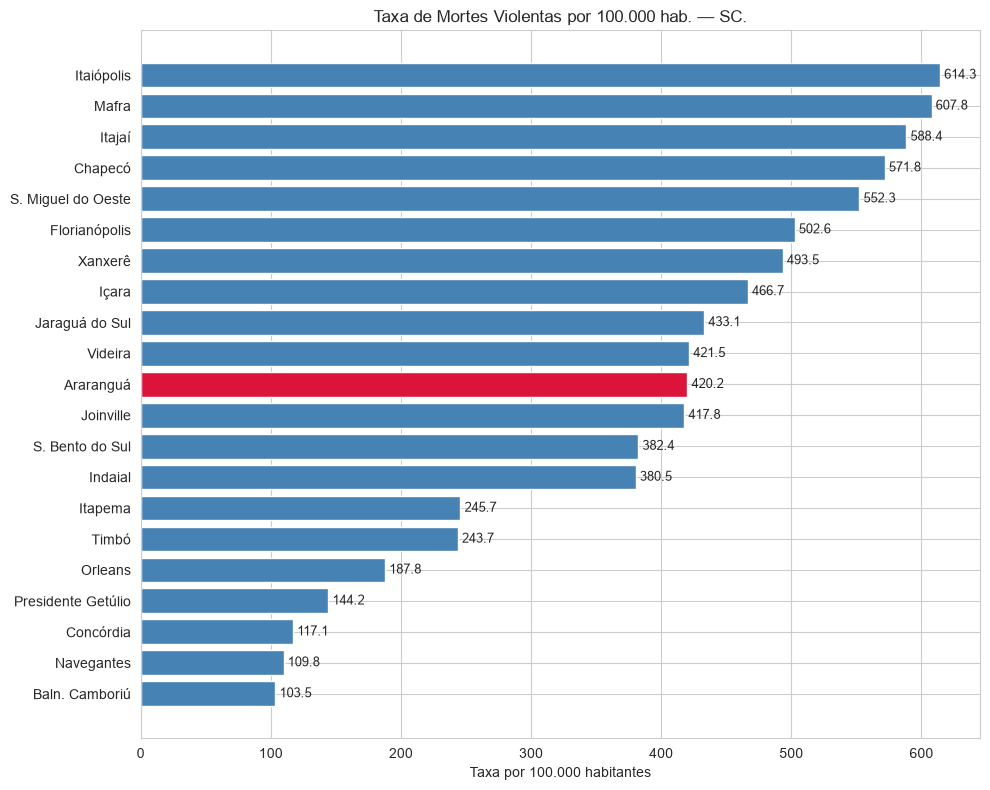

Araranguá ocupa a 20ª posição no ranking de taxa de SC
Total de municípios com dados de população: 34
Mortes violentas: 450 | Taxa: 420.2 por 100.000 hab.
Araranguá está entre os 58.8% municípios com maior taxa de mortes violentas em SC


In [73]:
# Populações dos principais municípios de SC — Censo IBGE 2022
pop_sc = {
    4209102: 616317,  # Joinville
    4205407: 516524,  # Florianópolis
    4202600: 361855,  # Blumenau
    4216909: 257506,  # São José
    4204202: 224013,  # Chapecó
    4208203: 230966,  # Itajaí
    4209300: 156727,  # Lages
    4208906: 183555,  # Jaraguá do Sul
    4211801: 210038,  # Palhoça
    4202107: 138159,  # Balneário Camboriú
    4219101: 107257,  # Tubarão
    4215802: 87080,   # São Bento do Sul
    4203006: 77082,   # Caçador
    4201406: 107089,  # Araranguá
    4210100: 57090,   # Mafra
    4213609: 35607,   # Porto União
    4209003: 32261,   # Joaçaba
    4209409: 50356,   # Laguna
    4219507: 48021,   # Xanxerê
    4217204: 40017,   # São Miguel do Oeste
    4219309: 55751,   # Videira
    4218202: 48007,   # Timbó
    4207007: 58919,   # Içara
    4207304: 48256,   # Imbituba
    4207502: 72793,   # Indaial
    4214805: 71264,   # Rio do Sul
    4203808: 52769,   # Canoinhas
    4204806: 38734,   # Curitibanos
    4216404: 52898,   # São Francisco do Sul
    4208302: 72453,   # Itapema
    4211504: 25033,   # Orleans
    4204509: 76022,   # Concórdia
    4211108: 75595,   # Navegantes
    4214003: 36055,   # Presidente Getúlio
    4208104: 25071,   # Itaiópolis
    4208302: 72453,   # Itapema
    4211504: 25033,   # Orleans
    4214003: 36055,   # Presidente Getúlio
    4204509: 76022,   # Concórdia
    4211108: 75595,   # Navegantes
    4208104: 25071,   # Itaiópolis
}
# Filtra mortes violentas em SC
df_violentas_sc = df[
    (df["SC_OCORRENCIA"] == True) & mascara_violenta
].dropna(subset=["LOCOCOR"]).copy()

# Contagem por município
contagem_municipios_sc = df_violentas_sc["CODMUNOCOR"].value_counts().reset_index()
contagem_municipios_sc.columns = ["CODMUNOCOR", "obitos"]

# Calcula taxa por 100.000 hab onde tiver população disponível
contagem_municipios_sc["pop"] = contagem_municipios_sc["CODMUNOCOR"].map(pop_sc)
contagem_municipios_sc["taxa"] = (
    contagem_municipios_sc["obitos"] / contagem_municipios_sc["pop"] * 100000
).round(1)

# Ordena por taxa
ranking_taxa = (
    contagem_municipios_sc.dropna(subset=["taxa"])
    .sort_values("taxa", ascending=False)
    .reset_index(drop=True)
)
ranking_taxa["posicao"] = ranking_taxa.index

pos_ararangua = ranking_taxa[ranking_taxa["CODMUNOCOR"] == CODIGO_ARARANGUA]

if len(pos_ararangua) > 0:
    idx = pos_ararangua.index[0]
    print(f"Araranguá: {pos_ararangua['obitos'].values[0]} mortes violentas")
    print(f"Taxa: {pos_ararangua['taxa'].values[0]:.1f} por 100.000 hab.")
    print(f"Posição no ranking de taxa: {idx + 1}º de {len(ranking_taxa)} municípios com dados de população")
    vizinhos = ranking_taxa.iloc[max(0, idx-10):idx+11].copy()
else:
    print("Araranguá não encontrada no ranking — verifique o código.")
    vizinhos = ranking_taxa.head(21).copy()

vizinhos["NOME"] = vizinhos["CODMUNOCOR"].map(mapa_municipios_abrev).fillna(vizinhos["CODMUNOCOR"].astype(str))
cores = ["crimson" if cod == CODIGO_ARARANGUA else "steelblue" for cod in vizinhos["CODMUNOCOR"]]

fig, ax = plt.subplots(figsize=(10, 8))
bars = ax.barh(vizinhos["NOME"], vizinhos["taxa"], color=cores)
plt.title("Taxa de Mortes Violentas por 100.000 hab. — SC.")
plt.xlabel("Taxa por 100.000 habitantes")
ax.invert_yaxis()

for bar in bars:
    ax.annotate(f"{bar.get_width():.1f}",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                xytext=(3, 0), textcoords="offset points",
                va="center", fontsize=9)

plt.tight_layout()
plt.show()

if len(pos_ararangua) > 0:
    posicao = idx + 1
    total = len(ranking_taxa)
    obitos = pos_ararangua['obitos'].values[0]
    taxa = pos_ararangua['taxa'].values[0]
    print(f"Araranguá ocupa a {posicao}ª posição no ranking de taxa de SC")
    print(f"Total de municípios com dados de população: {total}")
    print(f"Mortes violentas: {obitos} | Taxa: {taxa:.1f} por 100.000 hab.")
    print(f"Araranguá está entre os {round(posicao/total*100, 1)}% municípios com maior taxa de mortes violentas em SC")

Estar entre os municípios com mais mortes violentas em SC — equiparando-se a cidades turísticas e litorâneas com forte fluxo viário — confirma que a mortalidade externa em Araranguá não é isolada, exigindo políticas integradas de segurança pública e mobilidade urbana articuladas regionalmente com a macrorregião Sul e a rodovia BR-101.

## 5. Distribuição de Diagnósticos por Ambiente

A causa básica do óbito (campo CAUSABAS, codificado em CID-10) revela o tipo de evento que levou à morte. Cruzar essa informação com o local permite entender o perfil de cada ambiente.

In [74]:
mapa_cid = {
    # Acidentes de Transporte (V)
    "V031": "Pedestre: colisão c/ carro (rua)",
    "V039": "Pedestre: colisão c/ carro (n/esp.)",
    "V041": "Pedestre: colisão c/ veículo pesado",
    "V099": "Pedestre: acidente trânsito n/esp.",
    "V134": "Ciclista: colisão c/ carro",
    "V139": "Ciclista: acidente trânsito n/esp.",
    "V199": "Motociclista: acidente n/esp.",
    "V234": "Motociclista: colisão c/ triciclo",
    "V244": "Motociclista: colisão c/ carro",
    "V274": "Motociclista: colisão c/ objeto fixo",
    "V299": "Motociclista: acidente trânsito n/esp.",
    "V445": "Ocup. carro: colisão (comércio)",
    "V446": "Ocup. carro: colisão (área industrial)",
    "V475": "Ocup. carro: colisão c/ objeto fixo",
    "V476": "Ocup. carro: colisão c/ objeto fixo (ind.)",
    "V499": "Ocup. carro: acidente n/esp.",
    "V892": "Acidente trânsito: veículo n/esp.",
    "V899": "Acidente trânsito n/esp.",
    # Outros acidentes (W)
    "W190": "Queda não especificada",
    "W698": "Afogamento acidental",
    "W748": "Sufocação acidental",
    "W749": "Sufocação acidental n/esp.",
    "X599": "Exposição a fator acidental n/esp.",
    # Suicídios (X60-X84)
    "X600": "Suicídio: envenenamento (residência)",
    "X640": "Suicídio: autointoxicação p/ drogas",
    "X700": "Suicídio: enforcamento (residência)",
    "X701": "Suicídio: enforcamento (hab. coletiva)",
    "X708": "Suicídio: enforcamento (outro local)",
    "X709": "Suicídio: enforcamento n/esp.",
    "X718": "Suicídio: afogamento (outro local)",
    "X740": "Suicídio: arma de fogo (residência)",
    "X748": "Suicídio: arma de fogo (outro local)",
    "X809": "Suicídio: precipitação (outro local)",
    # Homicídios — arma de fogo maior porte (X93x)
    "X930": "Homicídio: arma de fogo maior (residência)",
    "X934": "Homicídio: arma de fogo maior (rua/estrada)",
    "X935": "Homicídio: arma de fogo maior (comércio)",
    "X936": "Exposição a forças da natureza (área industrial) ",
    "X938": "Homicídio: arma de fogo maior (outro local)",
    "X939": "Homicídio: arma de fogo maior (n/esp.)",
    # Homicídios — arma de fogo menor porte (X95x)
    "X950": "Homicídio: arma de fogo menor (residência)",
    "X954": "Homicídio: arma de fogo menor (rua/estrada)",
    "X959": "Homicídio: arma de fogo menor (n/esp.)",
    # Homicídios — objeto cortante (X99x)
    "X990": "Homicídio: objeto cortante (residência)",
    "X994": "Homicídio: objeto cortante (rua/estrada)",
    "X995": "Homicídio: objeto cortante (comércio)",
    "X999": "Homicídio: objeto cortante n/esp.",
    # Homicídios — outros meios
    "Y000": "Homicídio: objeto contundente (residência)",
    "Y004": "Homicídio: objeto contundente (rua/estrada)",
    "Y09":  "Homicídio: meio n/esp.",
    # Intervenção legal e indeterminados
    "Y349": "Evento de intenção indeterminada",
    "Y350": "Intervenção legal: arma de fogo",
    "R99":  "Causa de morte desconhecida",
    "R960": "Morte súbita",
}

def traduzir_cid(codigo):
    return mapa_cid.get(str(codigo), str(codigo))

# Cria coluna com descrição da causa
df_limpo["CAUSA_DESC"] = df_limpo["CAUSABAS"].apply(traduzir_cid)

In [75]:
# Tabela top 5 causas por local — com CIDs traduzidos
top_causas_por_local = (
    df_limpo.groupby("LOCOCOR")["CAUSA_DESC"]
    .apply(lambda x: x.value_counts().head(5))
)
top_causas_por_local

LOCOCOR                                                 
Domicilio    Suicídio: enforcamento (residência)            19
             Queda não especificada                          2
             Suicídio: arma de fogo (residência)             2
             Acidente trânsito: veículo n/esp.               2
             Homicídio: objeto cortante (residência)         2
Hospital     Acidente trânsito: veículo n/esp.              51
             Exposição a fator acidental n/esp.             41
             Pedestre: acidente trânsito n/esp.             10
             Evento de intenção indeterminada                6
             Afogamento acidental                            4
Ignorado     Acidente trânsito: veículo n/esp.               4
             Afogamento acidental                            3
             Homicídio: arma de fogo maior (rua/estrada)     1
             Homicídio: arma de fogo maior (comércio)        1
             Pedestre: acidente trânsito n/esp.              

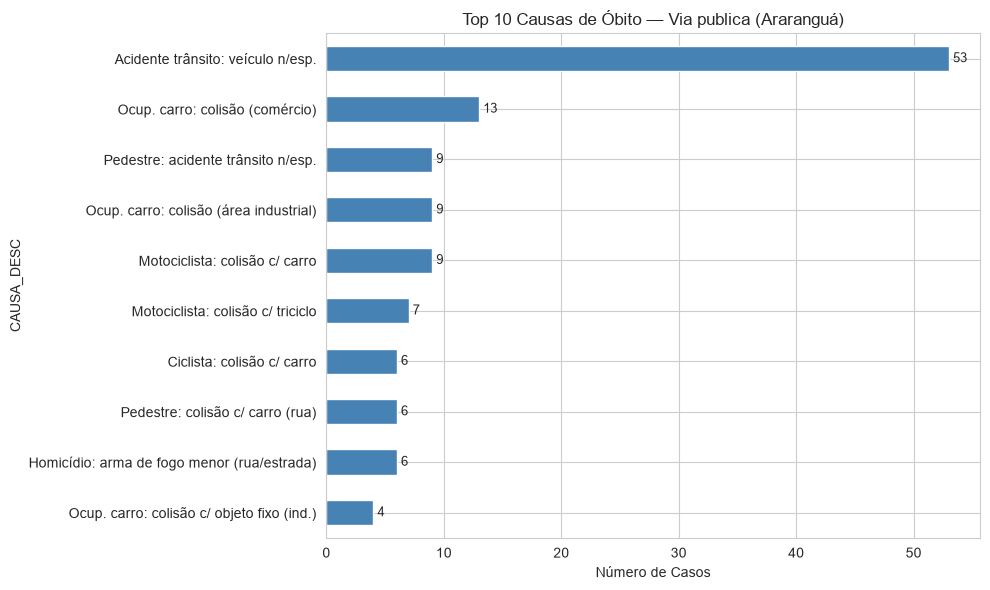

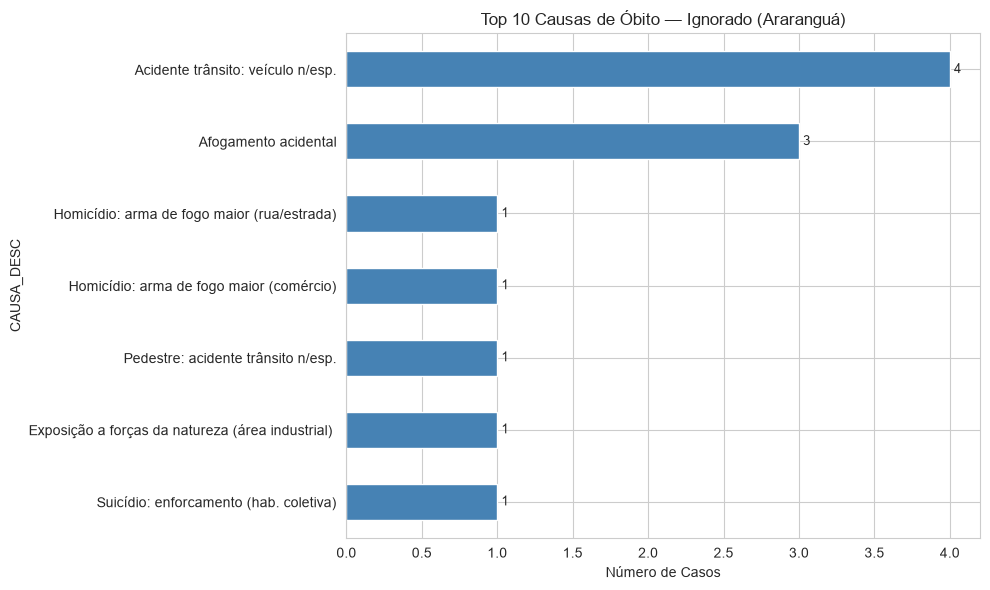

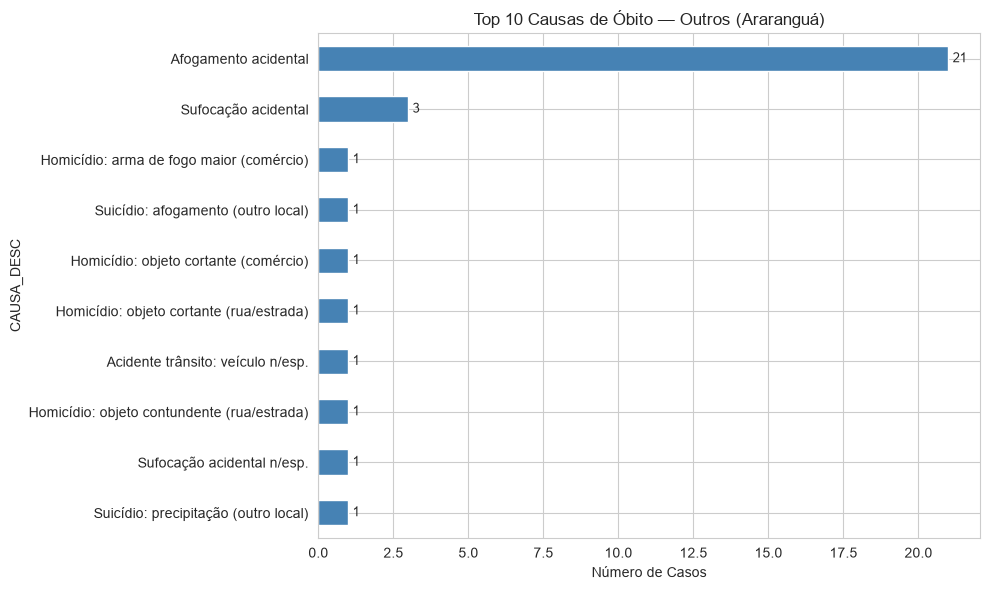

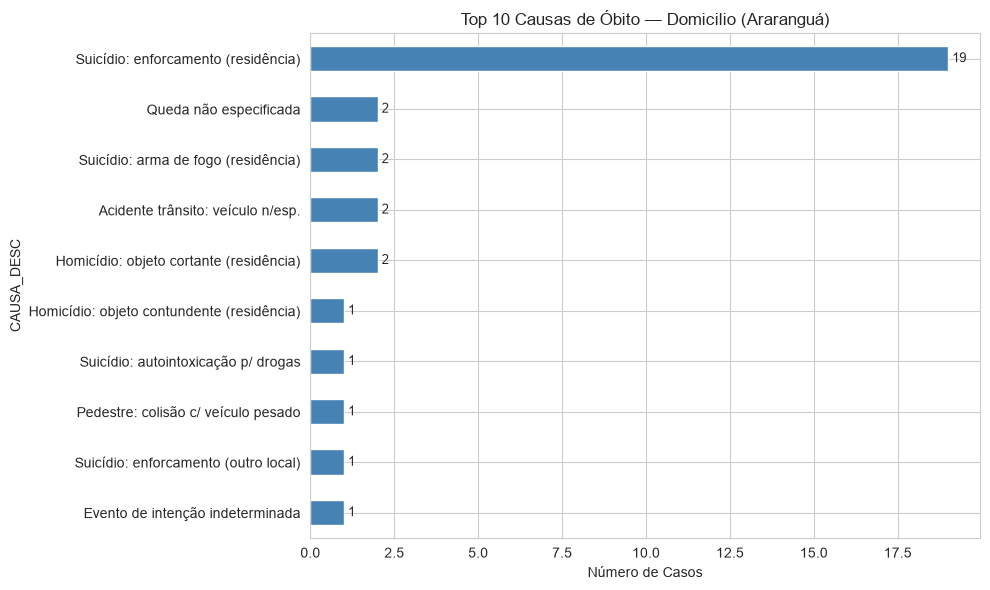

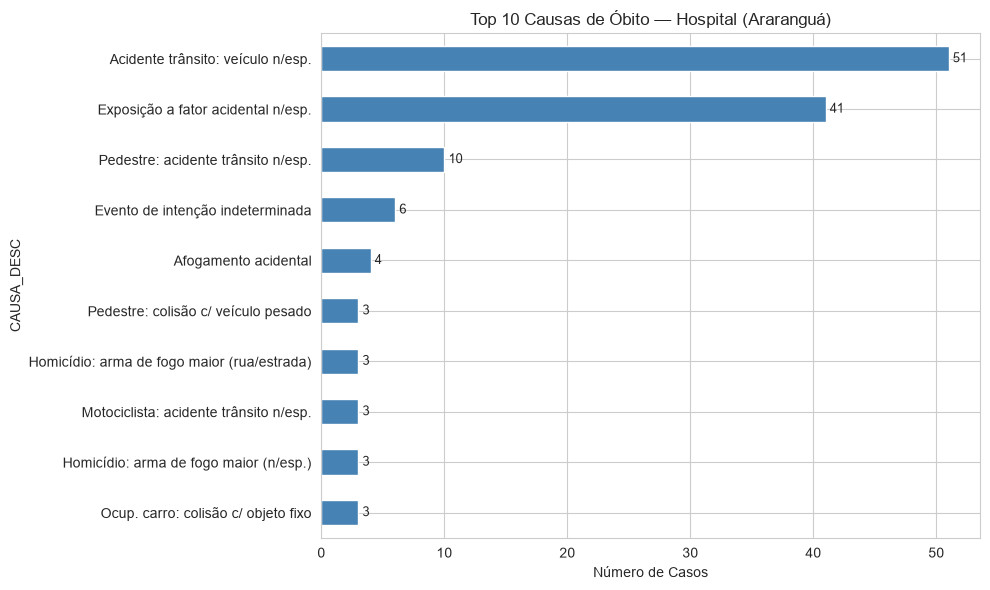

In [76]:
# Top 10 causas de óbito para cada local — um gráfico por local
locais = df_limpo["LOCOCOR"].dropna().unique()

for local in locais:
    causas_local = (
        df_limpo[df_limpo["LOCOCOR"] == local]["CAUSA_DESC"]
        .value_counts()
        .head(10)
    )

    if causas_local.empty:
        continue

    fig, ax = plt.subplots(figsize=(10, 6))
    causas_local.plot(kind="barh", ax=ax, color="steelblue")
    ax.invert_yaxis()
    ax.set_title(f"Top 10 Causas de Óbito — {local} (Araranguá)")
    ax.set_xlabel("Número de Casos")

    for bar in ax.patches:
        ax.annotate(f"{int(bar.get_width())}",
                    xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=9)

    plt.tight_layout()
    plt.show()

A segregação das causas por ambiente comprova que a violência em Araranguá tem dinâmicas distintas: os traumas urbanos/viários e as agressões exigem presença ostensiva de segurança e engenharia de tráfego nas ruas, enquanto os óbitos domiciliares demandam busca ativa da atenção primária e redes de apoio psicossocial para prevenção ao suicídio em ambiente privado.

## 6. Análise por Tipo de Morte Violenta — Acidentes, Homicídios e Suicídios

Classificar as mortes violentas por categoria permite entender a natureza dos eventos e direcionar políticas específicas para cada tipo.

In [77]:
def classificar_causa(cid):
    cid = str(cid)
    if cid.startswith("V") or cid.startswith("W") or (cid.startswith("X") and cid[1:3].isdigit() and int(cid[1:3]) <= 59):
        return "Acidente"
    elif cid.startswith("X") and cid[1:3].isdigit() and 60 <= int(cid[1:3]) <= 84:
        return "Suicídio"
    elif (cid.startswith("X") and cid[1:3].isdigit() and int(cid[1:3]) >= 85) or cid.startswith("Y0"):
        return "Homicídio"
    else:
        return "Outros/Indeterminado"

df_limpo["TIPO_VIOLENCIA"] = df_limpo["CAUSABAS"].astype(str).apply(classificar_causa)
print(df_limpo["TIPO_VIOLENCIA"].value_counts())

TIPO_VIOLENCIA
Acidente                347
Homicídio                49
Suicídio                 41
Outros/Indeterminado     13
Name: count, dtype: int64


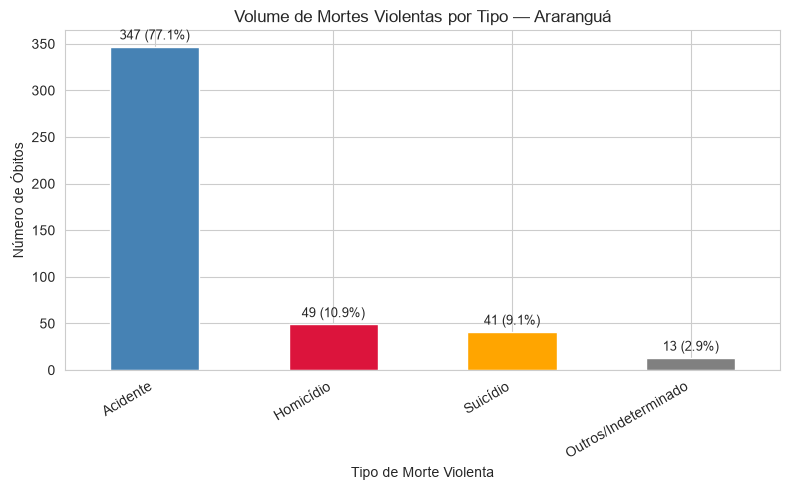

In [78]:
contagem_tipo = df_limpo["TIPO_VIOLENCIA"].value_counts()
total_tipo = contagem_tipo.sum()

fig, ax = plt.subplots(figsize=(8,5))
contagem_tipo.plot(kind="bar", ax=ax, color=["steelblue","crimson","orange","gray"])
plt.title("Volume de Mortes Violentas por Tipo — Araranguá")
plt.xlabel("Tipo de Morte Violenta")
plt.ylabel("Número de Óbitos")
plt.xticks(rotation=30, ha="right")

for bar in ax.patches:
    pct = bar.get_height() / total_tipo * 100
    ax.annotate(f"{int(bar.get_height())} ({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

A hegemonia absoluta dos acidentes demonstra que a principal ameaça à vida em termos de causas externas no município não é a criminalidade letal, mas sim o risco viário e acidental; isso indica que os maiores ganhos em preservação de vidas e redução de custos hospitalares virão prioritariamente de investimentos em engenharia de tráfego, sinalização e fiscalização viária.

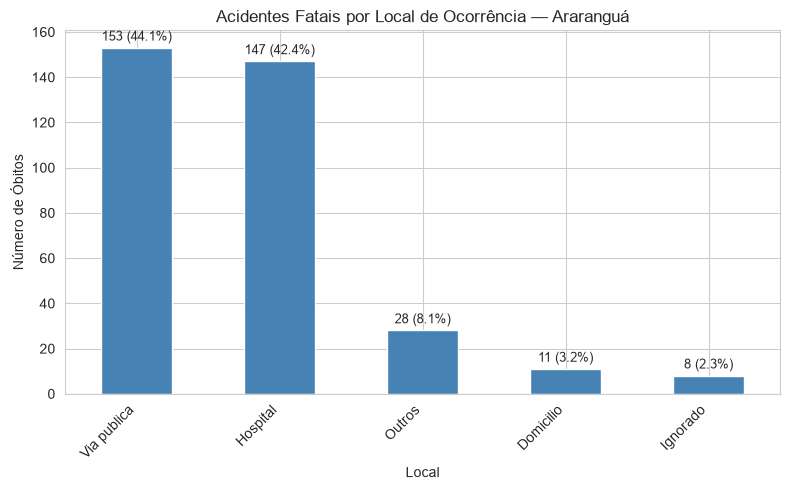

In [79]:
df_acidentes = df_limpo[df_limpo["TIPO_VIOLENCIA"] == "Acidente"]
contagem_acid_local = df_acidentes["LOCOCOR"].value_counts()
total_acid = contagem_acid_local.sum()

fig, ax = plt.subplots(figsize=(8,5))
contagem_acid_local.plot(kind="bar", ax=ax, color="steelblue")
plt.title("Acidentes Fatais por Local de Ocorrência — Araranguá")
plt.xlabel("Local")
plt.ylabel("Número de Óbitos")
plt.xticks(rotation=45, ha="right")

for bar in ax.patches:
    pct = bar.get_height() / total_acid * 100
    ax.annotate(f"{int(bar.get_height())} ({pct:.1f}%)",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 3), textcoords="offset points",
                ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show()

A divisão entre acidentes fatais em via pública e hospital aponta para um duplo desafio em Araranguá: a necessidade de medidas preventivas severas para conter o trauma instantâneo nas vias municipais e rodovias e, simultaneamente, o fortalecimento da capacidade de suporte avançado de trauma na rede hospitalar para aumentar a sobrevida dos pacientes admitidos.

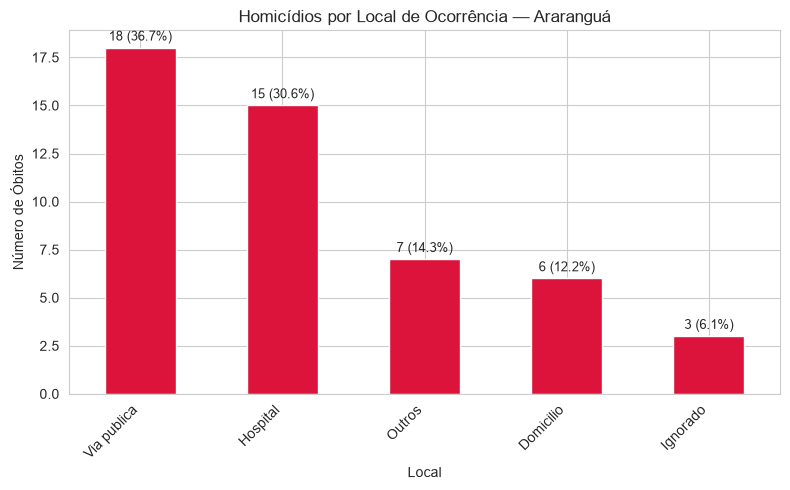

In [80]:
df_homicidios = df_limpo[df_limpo["TIPO_VIOLENCIA"] == "Homicídio"]

if len(df_homicidios) > 0:
    contagem_hom_local = df_homicidios["LOCOCOR"].value_counts()
    total_hom = contagem_hom_local.sum()

    fig, ax = plt.subplots(figsize=(8,5))
    contagem_hom_local.plot(kind="bar", ax=ax, color="crimson")
    plt.title("Homicídios por Local de Ocorrência — Araranguá")
    plt.xlabel("Local")
    plt.ylabel("Número de Óbitos")
    plt.xticks(rotation=45, ha="right")

    for bar in ax.patches:
        pct = bar.get_height() / total_hom * 100
        ax.annotate(f"{int(bar.get_height())} ({pct:.1f}%)",
                    xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points",
                    ha="center", va="bottom", fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print("Nenhum homicídio encontrado no recorte atual.")

A predominância de homicídios na **via pública** somada aos locais abertos evidencia o peso da violência interpessoal urbana e de conflitos de rua no município, demandando policiamento ostensivo e inteligência em pontos críticos; paralelamente, os registros em **domicílio** acendem o alerta para a violência doméstica fatal, exigindo fortalecimento da rede de proteção e atendimento à mulher e vulneráveis.

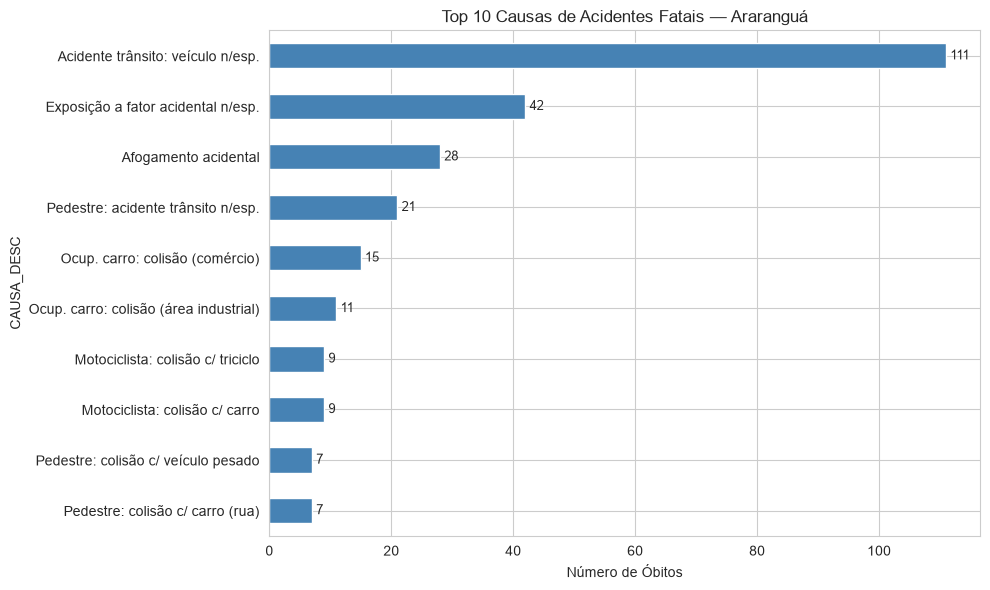

In [81]:
if len(df_acidentes) > 0:
    causas_acid = df_acidentes["CAUSA_DESC"].value_counts().head(10)

    fig, ax = plt.subplots(figsize=(10,6))
    causas_acid.plot(kind="barh", ax=ax, color="steelblue")
    plt.title("Top 10 Causas de Acidentes Fatais — Araranguá")
    plt.xlabel("Número de Óbitos")
    ax.invert_yaxis()

    for bar in ax.patches:
        ax.annotate(f"{int(bar.get_width())}",
                    xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=9)

    plt.tight_layout()
    plt.show()

A liderança massiva de sinistros de trânsito — somando pedestres, motociclistas e ocupantes de veículos — confirma que a infraestrutura viária e o comportamento no tráfego são os maiores vetores de mortalidade acidental na cidade, enquanto o volume relevante de **afogamentos** reflete o perfil geográfico litorâneo/fluvial de Araranguá, apontando para a urgência de reforçar a sinalização de risco e o efetivo de guarda-vidas em rios, lagoas e praias.

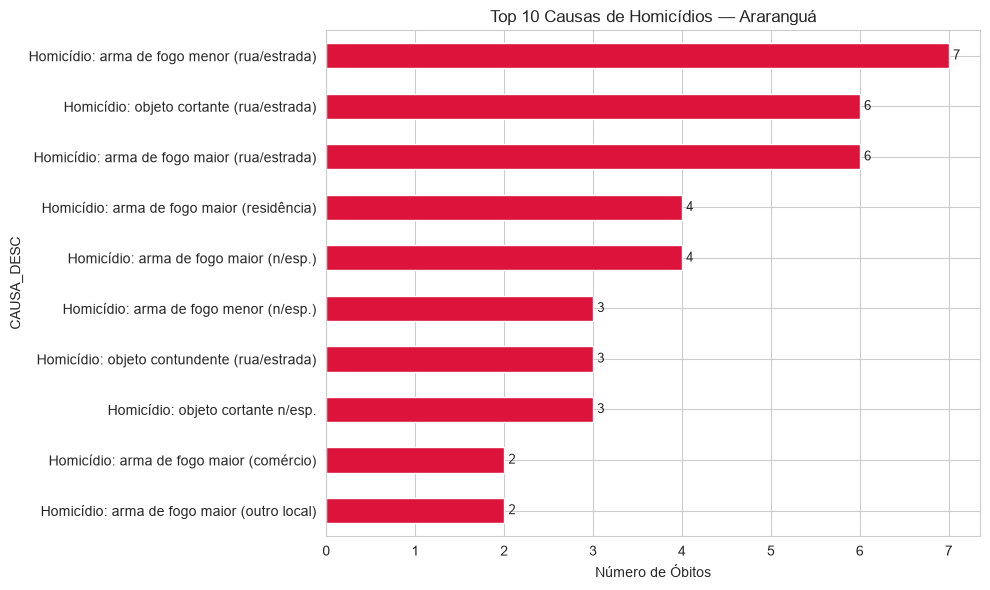

In [82]:
if len(df_homicidios) > 0:
    causas_hom = df_homicidios["CAUSA_DESC"].value_counts().head(10)

    fig, ax = plt.subplots(figsize=(10,6))
    causas_hom.plot(kind="barh", ax=ax, color="crimson")
    plt.title("Top 10 Causas de Homicídios — Araranguá")
    plt.xlabel("Número de Óbitos")
    ax.invert_yaxis()

    for bar in ax.patches:
        ax.annotate(f"{int(bar.get_width())}",
                    xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2),
                    xytext=(3, 0), textcoords="offset points",
                    va="center", fontsize=9)

    plt.tight_layout()
    plt.show()
else:
    print("Nenhum homicídio encontrado no recorte atual.")

A predominância de **armas de fogo em ambientes públicos** e de **objetos cortantes** no topo das agressões fatais evidencia que os homicídios em Araranguá estão atrelados tanto à circulação armada quanto a conflitos interpessoais de alta letalidade, indicando que as estratégias de combate devem combinar operações de apreensão de armas ilegais e reforço de patrulhamento ostensivo nos pontos de maior concentração de pessoas e vida noturna.